## REED 

### Setup Background

In [1]:
# without this, the module reed cannot be found for me, looking for the right solution here (tw)
import sys
sys.path.append(r'c:\Users\TimWeber\repos_20LCA\REED\reed\src')

In [2]:
import bw2data as bd
import bw2calc as bc
import bw2io as bi
from pathlib import Path
import pandas as pd
import seaborn as sns
import bw2analyzer as bwa
from reed.utils import Config

import matplotlib.pyplot as plt
import d3graph
import polyviz

15:07:53+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [3]:
config = Config()

In [4]:
bd.projects.set_current(config.PROJECT_NAME)

In [5]:
import import_db

In [6]:
bd.databases

Databases dictionary with 4 object(s):
	bonsai_231231
	bonsai_231231 biosphere
	ecoinvent-3.10-biosphere
	reed

### Install and Explore BONSAI

In [16]:
bonsai = bd.Database('bonsai_231231')
bonsai_bio = bd.Database('bonsai_231231 biosphere')
ecoinvent = bd.Database('ecoinvent-3.10-biosphere')
reed = bd.Database('reed')

In [15]:
from bw2io.importers import ExcelImporter
from reed.utils import Config

importer  = ExcelImporter(config.REED_PATH/'model'/'REED_model_20250829_tw.xlsx',)
importer.match_database(fields=['name','unit','location'])
importer.match_database(db_name=bonsai.name,fields=['name','unit','location','activity type'])
importer.write_database()

Extracted 3 worksheets in 0.12 seconds
Applying strategy: link_iterable_by_fields
Applying strategy: link_iterable_by_fields
15:12:21+0200 [warning  ] Not able to determine geocollections for all datasets. This database is not ready for regionalization.


100%|██████████| 7/7 [00:00<00:00, 746.36it/s]


15:12:21+0200 [info     ] Vacuuming database            
Created database: reed


In [17]:
pd.DataFrame(importer.unlinked)

""


In [18]:
data_reed = [activity.as_dict() for activity in reed]
df_reed = pd.DataFrame(data_reed)


In [19]:
from IPython.display import display
display(df_reed)

,code,comment,location,production amount,reference product,unit,name,worksheet name,database,type,id
0,electricity production,proxy,ES,1,electricity production,kilowatt hour,electricity production,LCA,reed,processwithreferenceproduct,38935
1,steel production,proxy,CN,1,steel production,kilogram,steel production,LCA,reed,processwithreferenceproduct,38933
2,"soraluce machine, WWR",This process represents the materials for the ...,DE,1,"soraluce machine, WWR",unit,"soraluce machine, WWR",LCA,reed,processwithreferenceproduct,38937
3,welding,process modelled as foreground activity,Global,1,welding,meter,welding,LCA,reed,processwithreferenceproduct,38932
4,"soraluce machine, Goimek",This process represents the materials for the ...,DE,1,"soraluce machine, Goimek",unit,"soraluce machine, Goimek",LCA,reed,processwithreferenceproduct,38938
5,cast iron production,proxy,CN,1,cast iron production,kilogram,cast iron production,LCA,reed,processwithreferenceproduct,38934
6,"soraluce machine, Komatsu",This process represents the materials for the ...,GB,1,"soraluce machine, Komatsu",unit,"soraluce machine, Komatsu",LCA,reed,processwithreferenceproduct,38936


### LCA scores

In [20]:
bonsai.search('chemical es')

['chemical and fertilizer minerals' (tonne, ES, None),
 'chemical and fertilizer minerals' (tonne, ES, None),
 'fuel mix and combustion for chemical and petrochemical' (TJ, ES, None)]

In [21]:
reed.search('steel')

['steel production' (kilogram, CN, None)]

In [22]:
bonsai_bio.search('carbon')

['carbon dioxide accelerated' (tonne, None, ('air',))]

In [23]:
steel = reed.get(name = 'steel production', location = "CN", unit = 'kilogram')
welding = reed.get(name = 'welding', location = "Global", unit = 'meter')
soraluce_wwr = reed.get(name = 'soraluce machine, WWR', location = "DE", unit = 'unit')

In [24]:
steel_lca = steel.lca(config.lcia_gwp100)
steel_lca.score

3.699659111742151

In [25]:
welding_lca = welding.lca(config.lcia_gwp100)
welding_lca.score

0.19874255716070371

In [26]:
soraluce_wwr_lca = soraluce_wwr.lca(config.lcia_gwp100)
soraluce_wwr_lca.score

291049.7307757704

### Contribution analysis

In [ ]:
bwa.print_recursive_calculation(steel,
lcia_method=config.lcia_gwp100,max_level=5,cutoff=0.01)

In [ ]:
bwa.print_recursive_calculation(soraluce_wwr,
lcia_method=config.lcia_gwp100,max_level=5,cutoff=0.01)

This graph is extracted using ecoinvent v3.10 consequential and brightway 2.5 and can help us identify key processes to study when modelling the foreground of REED

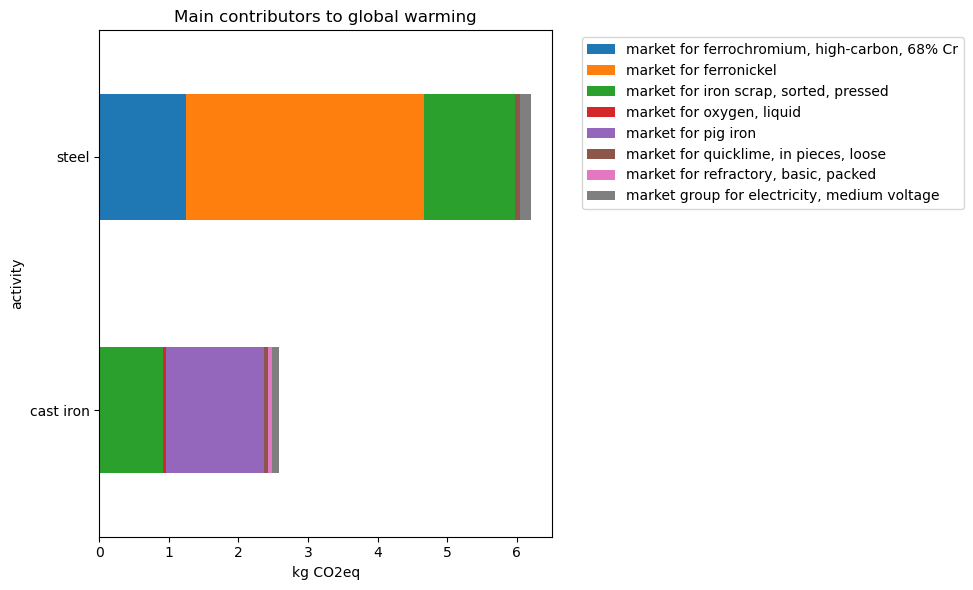

In [29]:
arc_welding_ecoinvent = 0.2020495074178421

This graph compares arc metal welding and gas welding from ecoinvent and shows that most of the climate impact is from the filler material in all cases

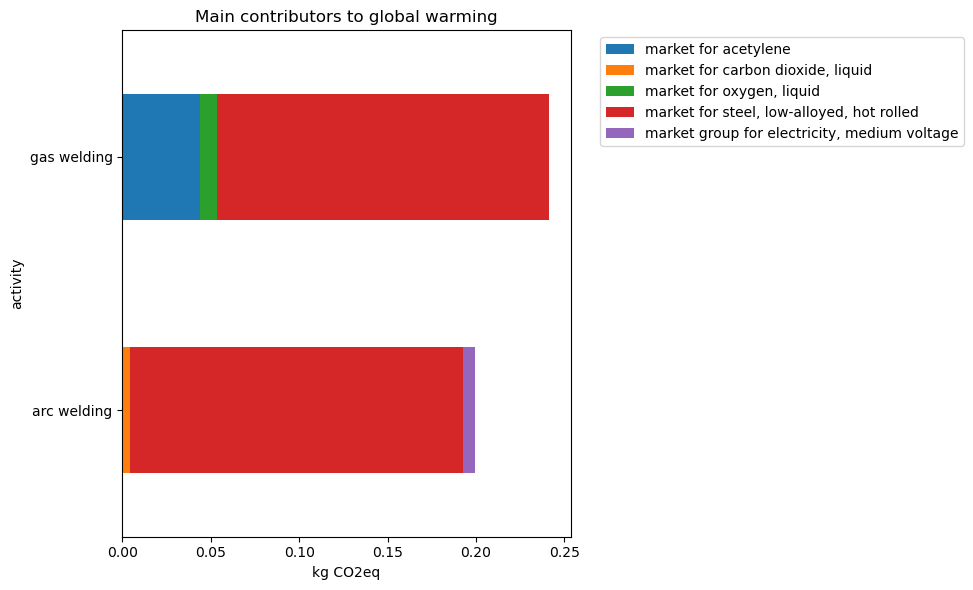